# Project 1: Sales Performance Analysis with Python
**Program:** Data Analytics, Axionz Global Pvt Ltd  |  **Tools:** Pandas, NumPy, Matplotlib, Seaborn

## 1. Business Question
A retailer selling computers, monitors, storage, networking gear, accessories and office supplies through four sales channels in five regions wants to know:

> **Where does our 2026 revenue really come from, and which products, channels, regions, customer groups and months should we focus on to grow it?**

Sub-questions: (a) Which product categories drive revenue? (b) Which channels and regions perform best? (c) Do returning customers matter more than new ones? (d) Is there seasonality? (e) Do discounts actually lift order size? (f) How concentrated is revenue in a few large orders?

## 2. Dataset
| Item | Detail |
|---|---|
| File | `Data (2).xlsx` (sheet `Data`), stored as `data/raw/sales_data_raw.xlsx` |
| Size | 2,000 orders x 12 columns |
| Period | 1 Jan 2026 to 31 Dec 2026 |

| Column | Meaning |
|---|---|
| Order ID | Unique order number |
| Date | Order date |
| Region | North, South, East, West, Central |
| Sales Channel | Online, Retail Store, Marketplace, Corporate Sales |
| Customer Type | New or Returning |
| Product Category / Product | 6 categories, 28 products |
| Salesperson | 15 sales staff |
| Quantity, Unit Price, Discount | Units sold, price per unit, discount fraction |
| Revenue | Net order value after discount |

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi':100,'axes.titleweight':'bold','axes.titlesize':13})
pd.options.display.float_format='{:,.2f}'.format
IMG='images/'

## 3. Load and Inspect the Data

In [2]:
df_raw = pd.read_excel('data/raw/sales_data_raw.xlsx')
df = df_raw.copy()
print('Shape (rows, columns):', df.shape)
df.head()

Shape (rows, columns): (2000, 12)


,Order ID,Date,Region,Sales Channel,Customer Type,Product Category,Product,Salesperson,Quantity,Unit Price,Discount,Revenue
0,ORD-1001,2026-01-09 00:00:00,West,Online,New,Accessories,Mouse Pad,Sofia Tan,4,13.10,0.00,52.38
1,ORD-1002,3/17/2026,East,Retail Store,Returning,Storage,Memory Card 256GB,Nora Chen,3,81.00,0.03,235.71
2,ORD-1003,2026-06-10 00:00:00,West,Online,New,Networking,Ethernet Cable,Ben Ho,2,17.46,0.00,34.92
3,ORD-1004,8/26/2026,North,Retail Store,New,Networking,Wi-Fi Router,Aisha Lim,6,252.00,0.05,"1,436.40"
4,ORD-1005,8/23/2026,North,Corporate Sales,Returning,Networking,Mesh Wi-Fi Set,Aisha Lim,7,654.75,0.05,"4,354.09"


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          2000 non-null   str    
 1   Date              2000 non-null   object 
 2   Region            2000 non-null   str    
 3   Sales Channel     2000 non-null   str    
 4   Customer Type     2000 non-null   str    
 5   Product Category  2000 non-null   str    
 6   Product           2000 non-null   str    
 7   Salesperson       2000 non-null   str    
 8   Quantity          2000 non-null   int64  
 9   Unit Price        2000 non-null   float64
 10  Discount          2000 non-null   float64
 11  Revenue           2000 non-null   float64
dtypes: float64(3), int64(1), object(1), str(7)
memory usage: 187.6+ KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,"2,000.00",3.78,2.12,2.00,2.00,3.00,5.00,16.00
Unit Price,"2,000.00",678.86,"1,015.01",6.84,38.48,162.00,726.75,"4,006.80"
Discount,"2,000.00",0.07,0.05,0.00,0.03,0.08,0.10,0.20
Revenue,"2,000.00","1,731.30","2,473.50",11.17,125.97,521.16,"2,444.40","18,083.52"


In [5]:
# Date is stored in two different ways - check before cleaning
print(df['Date'].map(lambda v: type(v).__name__).value_counts())
print()
print('Sample text dates:', df.loc[df['Date'].map(lambda v: isinstance(v,str)),'Date'].head(5).tolist())

Date
str         1215
datetime     785
Name: count, dtype: int64

Sample text dates: ['3/17/2026', '8/26/2026', '8/23/2026', '4/19/2026', '12/30/2026']


## 4. Data Cleaning
Each decision and the reason for it:

**4.1 Dates.** The `Date` column mixes true Excel dates with text such as `3/17/2026`. Because the day part exceeds 12 in some text values (e.g. `8/26/2026`) and the month never does, the text format is confirmed as **month/day/year**. We convert everything to a single `datetime` type.

In [6]:
txt = df['Date'].map(lambda v: isinstance(v,str))
first_part  = df.loc[txt,'Date'].str.split('/').str[0].astype(int)
second_part = df.loc[txt,'Date'].str.split('/').str[1].astype(int)
print('Text dates where first number > 12 :', (first_part>12).sum())
print('Text dates where second number > 12:', (second_part>12).sum(), '-> format is M/D/YYYY')

df['Date'] = [pd.to_datetime(v, format='%m/%d/%Y') if isinstance(v,str) else pd.Timestamp(v) for v in df['Date']]
print('\nDate dtype now:', df['Date'].dtype)
print('Range:', df['Date'].min().date(), 'to', df['Date'].max().date())

Text dates where first number > 12 : 0
Text dates where second number > 12: 1215 -> format is M/D/YYYY

Date dtype now: datetime64[us]
Range: 2026-01-01 to 2026-12-31


**4.2 Missing values and duplicates.**

In [7]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0] if df.isna().any().any() else 'None - no missing values')
print('\nDuplicate Order IDs      :', df['Order ID'].duplicated().sum())
print('Fully duplicated rows    :', df.duplicated().sum())
print('Duplicates ignoring Order ID:', df.drop(columns='Order ID').duplicated().sum())

Missing values per column:
None - no missing values

Duplicate Order IDs      : 0
Fully duplicated rows    : 0
Duplicates ignoring Order ID: 0


**4.3 Text consistency and data types.** Check categorical columns for spelling/spacing variants, and set suitable types.

In [8]:
cat_cols=['Region','Sales Channel','Customer Type','Product Category','Product','Salesperson']
for c in cat_cols:
    df[c]=df[c].str.strip()
    print(f'{c:17s}', df[c].nunique(), 'unique values')
df[cat_cols]=df[cat_cols].astype('category')
# Each product should belong to exactly one category
print('\nProducts mapped to more than one category:', (df.groupby('Product',observed=True)['Product Category'].nunique()>1).sum())

Region            5 unique values
Sales Channel     4 unique values
Customer Type     2 unique values
Product Category  6 unique values
Product           28 unique values
Salesperson       15 unique values

Products mapped to more than one category: 0


**4.4 Logical validation.** Revenue should equal `Quantity x Unit Price x (1 - Discount)`. Values should also be positive and discounts between 0 and 1.

In [9]:
calc = (df['Quantity']*df['Unit Price']*(1-df['Discount'])).round(2)
diff = (calc-df['Revenue']).abs()
print('Max difference between calculated and recorded Revenue: %.2f' % diff.max())
print('Rows differing by more than 0.10:', (diff>0.10).sum())
print('Non-positive Quantity/Price/Revenue:', ((df[['Quantity','Unit Price','Revenue']]<=0).any(axis=1)).sum())
print('Discount range:', df['Discount'].min(), 'to', df['Discount'].max())

Max difference between calculated and recorded Revenue: 0.07
Rows differing by more than 0.10: 0
Non-positive Quantity/Price/Revenue: 0
Discount range: 0.0 to 0.2


Revenue matches the formula to within rounding (the largest difference is 7 cents), so the numbers are internally consistent.

**4.5 Outliers.** We use the IQR rule on `Revenue` and `Quantity`.

In [10]:
for c in ['Revenue','Quantity']:
    q1,q3=df[c].quantile([.25,.75]); iqr=q3-q1; hi=q3+1.5*iqr
    print(f'{c}: upper fence = {hi:,.1f}, outliers = {(df[c]>hi).sum()} ({(df[c]>hi).mean():.1%})')
big = df[df['Revenue']>df['Revenue'].quantile(.75)+1.5*(df['Revenue'].quantile(.75)-df['Revenue'].quantile(.25))]
print('\nCategories of high-revenue outliers:'); print(big['Product Category'].value_counts())

Revenue: upper fence = 5,922.1, outliers = 147 (7.3%)
Quantity: upper fence = 9.5, outliers = 35 (1.8%)

Categories of high-revenue outliers:
Product Category
Computers          141
Monitors             4
Networking           1
Storage              1
Accessories          0
Office Supplies      0
Name: count, dtype: int64


**Decision: keep all outliers.** The high-revenue orders are almost all Computers (and some Monitors), which are legitimately expensive. They are real sales, not errors, and removing them would hide the most important part of the business. Large quantities (up to 16) are plausible for cheap items such as cables and office supplies. We use the **median** alongside the mean when describing typical orders.

**4.6 Feature engineering** for later analysis.

In [11]:
df['Month']      = df['Date'].dt.month
df['Month Name'] = df['Date'].dt.strftime('%b')
df['Quarter']    = 'Q' + df['Date'].dt.quarter.astype(str)
df['Weekday']    = df['Date'].dt.day_name()
df['Gross Sales']      = df['Quantity']*df['Unit Price']
df['Discount Amount']  = (df['Gross Sales']-df['Revenue']).round(2)
df['Discount Band']    = pd.cut(df['Discount'],[-0.01,0,0.05,0.10,0.20],labels=['None','1-5%','6-10%','11-20%'])
df.to_csv('data/cleaned/sales_data_cleaned.csv',index=False)
print('Cleaned shape:', df.shape); df.head()

Cleaned shape: (2000, 19)


,Order ID,Date,Region,Sales Channel,Customer Type,Product Category,Product,Salesperson,Quantity,Unit Price,Discount,Revenue,Month,Month Name,Quarter,Weekday,Gross Sales,Discount Amount,Discount Band
0,ORD-1001,2026-01-09,West,Online,New,Accessories,Mouse Pad,Sofia Tan,4,13.10,0.00,52.38,1,Jan,Q1,Friday,52.40,0.02,None
1,ORD-1002,2026-03-17,East,Retail Store,Returning,Storage,Memory Card 256GB,Nora Chen,3,81.00,0.03,235.71,3,Mar,Q1,Tuesday,243.00,7.29,1-5%
2,ORD-1003,2026-06-10,West,Online,New,Networking,Ethernet Cable,Ben Ho,2,17.46,0.00,34.92,6,Jun,Q2,Wednesday,34.92,0.00,None
3,ORD-1004,2026-08-26,North,Retail Store,New,Networking,Wi-Fi Router,Aisha Lim,6,252.00,0.05,"1,436.40",8,Aug,Q3,Wednesday,"1,512.00",75.60,1-5%
4,ORD-1005,2026-08-23,North,Corporate Sales,Returning,Networking,Mesh Wi-Fi Set,Aisha Lim,7,654.75,0.05,"4,354.09",8,Aug,Q3,Sunday,"4,583.25",229.16,1-5%


## 5. Exploratory Data Analysis (EDA)

### 5.1 Headline KPIs

In [12]:
kpi = pd.Series({
 'Total Revenue': df['Revenue'].sum(),
 'Orders': len(df),
 'Average Order Value (mean)': df['Revenue'].mean(),
 'Median Order Value': df['Revenue'].median(),
 'Units Sold': df['Quantity'].sum(),
 'Total Discount Given': df['Discount Amount'].sum(),
 'Discount as % of Gross Sales': df['Discount Amount'].sum()/df['Gross Sales'].sum()*100,
})
kpi.to_frame('Value')

,Value
Total Revenue,"3,462,605.32"
Orders,"2,000.00"
Average Order Value (mean),"1,731.30"
Median Order Value,521.16
Units Sold,"7,552.00"
Total Discount Given,"280,963.36"
Discount as % of Gross Sales,7.51


### 5.2 Distributions

In [13]:
df[['Quantity','Unit Price','Discount','Revenue']].agg(['mean','median','std','min','max']).T

,mean,median,std,min,max
Quantity,3.78,3.00,2.12,2.00,16.00
Unit Price,678.86,162.00,"1,015.01",6.84,"4,006.80"
Discount,0.07,0.08,0.05,0.00,0.20
Revenue,"1,731.30",521.16,"2,473.50",11.17,"18,083.52"


### 5.3 GroupBy and aggregation

In [14]:
def summarise(col):
    g = df.groupby(col,observed=True).agg(Revenue=('Revenue','sum'), Orders=('Order ID','count'),
            Avg_Order_Value=('Revenue','mean'), Avg_Discount=('Discount','mean'))
    g['Revenue Share %'] = g['Revenue']/g['Revenue'].sum()*100
    return g.sort_values('Revenue',ascending=False)
summarise('Product Category')

,Revenue,Orders,Avg_Order_Value,Avg_Discount,Revenue Share %
Product Category,,,,,
Computers,"2,058,536.24",338,"6,090.34",0.08,59.45
Monitors,"737,406.12",353,"2,088.97",0.07,21.30
Networking,"291,619.52",231,"1,262.42",0.07,8.42
Storage,"269,998.05",329,820.66,0.08,7.80
Accessories,"85,917.49",503,170.81,0.07,2.48
Office Supplies,"19,127.90",246,77.76,0.07,0.55


In [15]:
summarise('Sales Channel')

,Revenue,Orders,Avg_Order_Value,Avg_Discount,Revenue Share %
Sales Channel,,,,,
Online,"1,112,657.22",789,"1,410.21",0.07,32.13
Corporate Sales,"1,013,948.69",333,"3,044.89",0.08,29.28
Retail Store,"906,981.87",508,"1,785.40",0.07,26.19
Marketplace,"429,017.54",370,"1,159.51",0.08,12.39


In [16]:
summarise('Region')

,Revenue,Orders,Avg_Order_Value,Avg_Discount,Revenue Share %
Region,,,,,
Central,"802,603.64",431,"1,862.19",0.08,23.18
North,"787,107.33",478,"1,646.67",0.08,22.73
East,"658,276.02",394,"1,670.75",0.07,19.01
South,"627,690.52",367,"1,710.33",0.07,18.13
West,"586,927.81",330,"1,778.57",0.07,16.95


In [17]:
summarise('Customer Type')

,Revenue,Orders,Avg_Order_Value,Avg_Discount,Revenue Share %
Customer Type,,,,,
Returning,"2,368,353.98",1311,"1,806.52",0.08,68.40
New,"1,094,251.34",689,"1,588.17",0.07,31.60


In [18]:
summarise('Salesperson')

,Revenue,Orders,Avg_Order_Value,Avg_Discount,Revenue Share %
Salesperson,,,,,
Mei Tan,"319,585.32",169,"1,891.04",0.07,9.23
Hafiz Rahman,"288,782.83",148,"1,951.24",0.07,8.34
Chloe Lim,"274,073.97",144,"1,903.29",0.08,7.92
Amir Hassan,"268,593.79",133,"2,019.50",0.08,7.76
Raj Kumar,"258,622.62",141,"1,834.20",0.07,7.47
Aisha Lim,"242,303.51",161,"1,504.99",0.08,7.00
Kevin Yap,"239,746.84",139,"1,724.80",0.07,6.92
Sofia Tan,"227,194.25",111,"2,046.80",0.07,6.56
Daniel Wong,"225,218.50",148,"1,521.75",0.08,6.50


In [19]:
df.groupby('Product',observed=True)['Revenue'].sum().sort_values(ascending=False).head(10).to_frame('Revenue')

,Revenue
Product,
Gaming Laptop,"665,930.53"
Laptop Pro 14,"404,051.34"
Laptop Air 13,"403,380.02"
All-in-One PC,"389,723.94"
Ultrawide Monitor,"271,543.21"
27-inch Monitor,"208,007.44"
Desktop Mini,"195,450.41"
Mesh Wi-Fi Set,"179,979.94"
External SSD 1TB,"138,129.45"


### 5.4 Correlations

In [20]:
num = df[['Quantity','Unit Price','Discount','Revenue']]
num.corr().round(2)

,Quantity,Unit Price,Discount,Revenue
Quantity,1.00,-0.32,0.04,-0.13
Unit Price,-0.32,1.00,0.02,0.91
Discount,0.04,0.02,1.00,-0.02
Revenue,-0.13,0.91,-0.02,1.00


## 6. Visualisation

### Chart 1: Revenue by product category

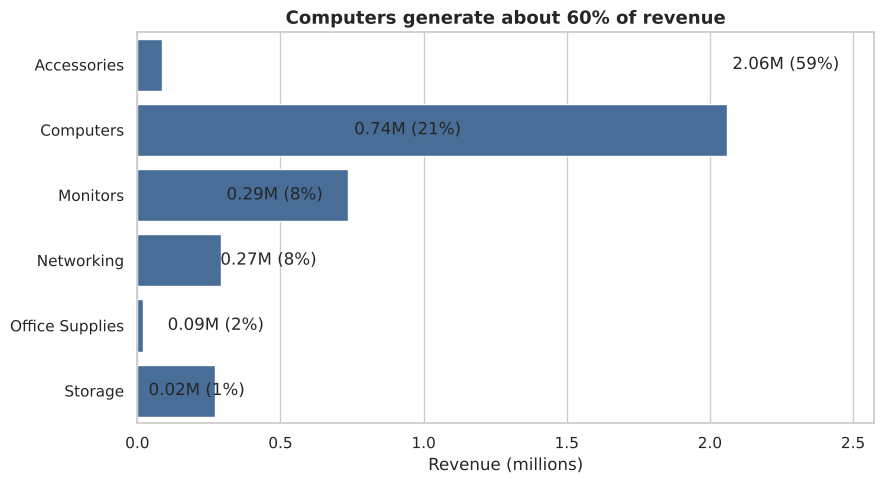

In [21]:
order = summarise('Product Category').index
fig,ax=plt.subplots(figsize=(9,5))
s=summarise('Product Category')['Revenue']/1e6
sns.barplot(x=s.values,y=s.index,ax=ax,color='#3b6ea5')
for i,v in enumerate(s.values): ax.text(v+0.02,i,f'{v:.2f}M ({v/s.sum():.0%})',va='center')
ax.set_title('Computers generate about 60% of revenue'); ax.set_xlabel('Revenue (millions)'); ax.set_ylabel('')
ax.set_xlim(0,s.max()*1.25); plt.tight_layout(); plt.savefig(IMG+'01_revenue_by_category.png'); plt.show()

### Chart 2: Monthly revenue trend

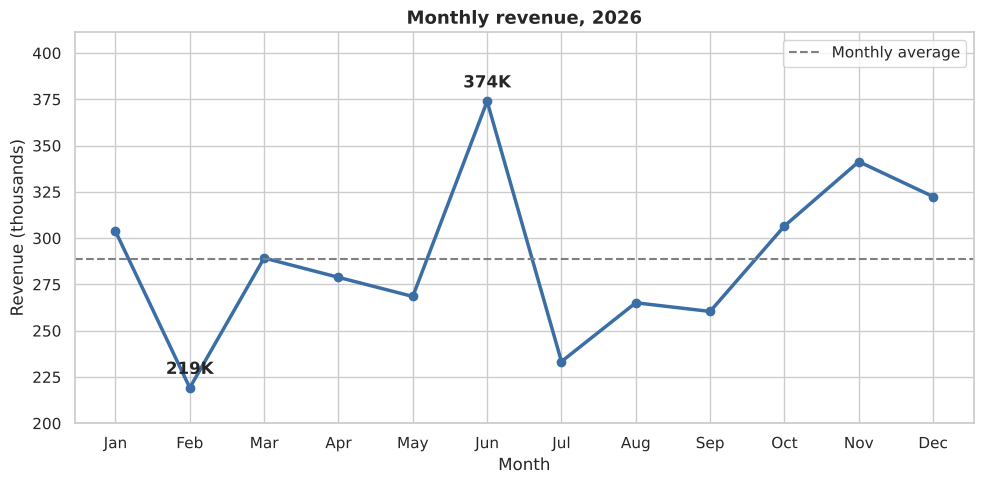

In [22]:
m=df.groupby('Month').agg(Revenue=('Revenue','sum'),Orders=('Order ID','count')).reset_index()
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(m['Month'],m['Revenue']/1e3,marker='o',lw=2.5,color='#3b6ea5')
ax.axhline(m['Revenue'].mean()/1e3,ls='--',color='grey',label='Monthly average')
for _,r in m.iterrows():
    if r['Month'] in (m.loc[m.Revenue.idxmax(),'Month'], m.loc[m.Revenue.idxmin(),'Month']):
        ax.annotate(f"{r['Revenue']/1e3:,.0f}K",(r['Month'],r['Revenue']/1e3),textcoords='offset points',xytext=(0,10),ha='center',fontweight='bold')
ax.set_xticks(range(1,13)); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_ylim(200,m['Revenue'].max()/1e3*1.1); ax.set_title('Monthly revenue, 2026'); ax.set_xlabel('Month'); ax.set_ylabel('Revenue (thousands)'); ax.legend()
plt.tight_layout(); plt.savefig(IMG+'02_monthly_revenue.png'); plt.show()

### Chart 3: Revenue and average order value by sales channel

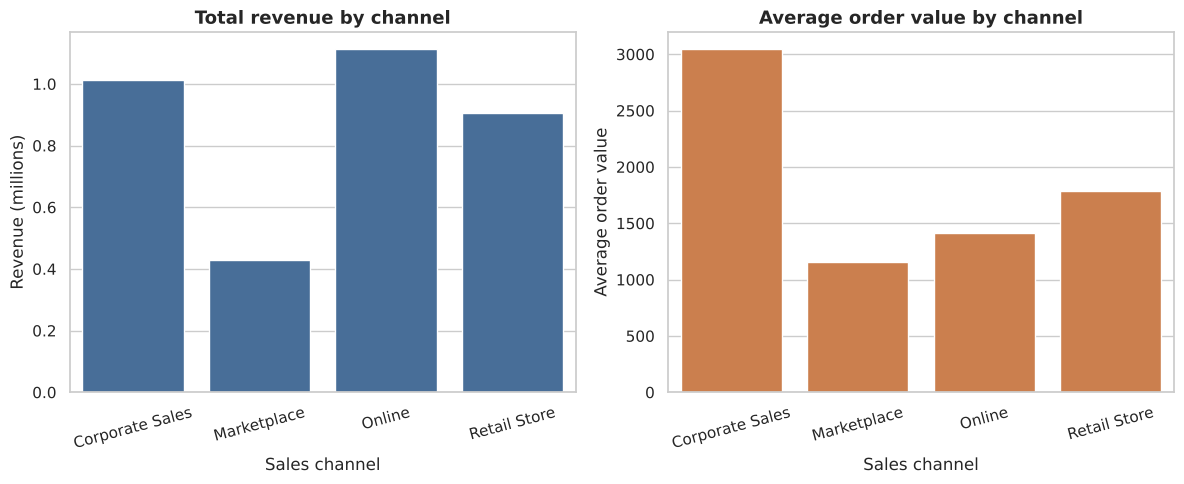

In [23]:
ch=summarise('Sales Channel')
fig,ax=plt.subplots(1,2,figsize=(12,5))
sns.barplot(x=ch.index,y=ch['Revenue']/1e6,ax=ax[0],color='#3b6ea5'); ax[0].set_title('Total revenue by channel'); ax[0].set_ylabel('Revenue (millions)'); ax[0].set_xlabel('Sales channel')
sns.barplot(x=ch.index,y=ch['Avg_Order_Value'],ax=ax[1],color='#e07b39'); ax[1].set_title('Average order value by channel'); ax[1].set_ylabel('Average order value'); ax[1].set_xlabel('Sales channel')
for a in ax: a.tick_params(axis='x',rotation=15)
plt.tight_layout(); plt.savefig(IMG+'03_channel.png'); plt.show()

### Chart 4: Revenue by region and customer type

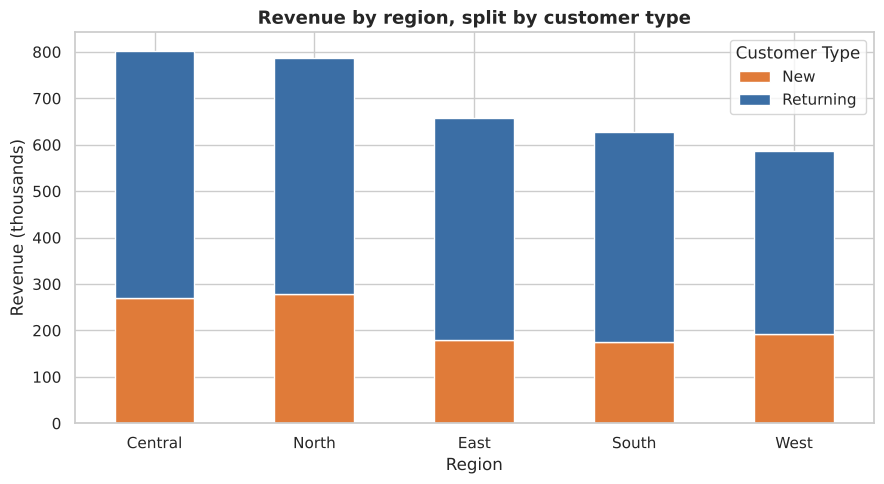

In [24]:
rc=df.pivot_table(index='Region',columns='Customer Type',values='Revenue',aggfunc='sum',observed=True)/1e3
rc=rc.loc[rc.sum(axis=1).sort_values(ascending=False).index]
ax=rc.plot(kind='bar',stacked=True,figsize=(9,5),color=['#e07b39','#3b6ea5'])
ax.set_title('Revenue by region, split by customer type'); ax.set_ylabel('Revenue (thousands)'); ax.set_xlabel('Region'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(IMG+'04_region_customer.png'); plt.show()

### Chart 5: Order value distribution (log scale) by category

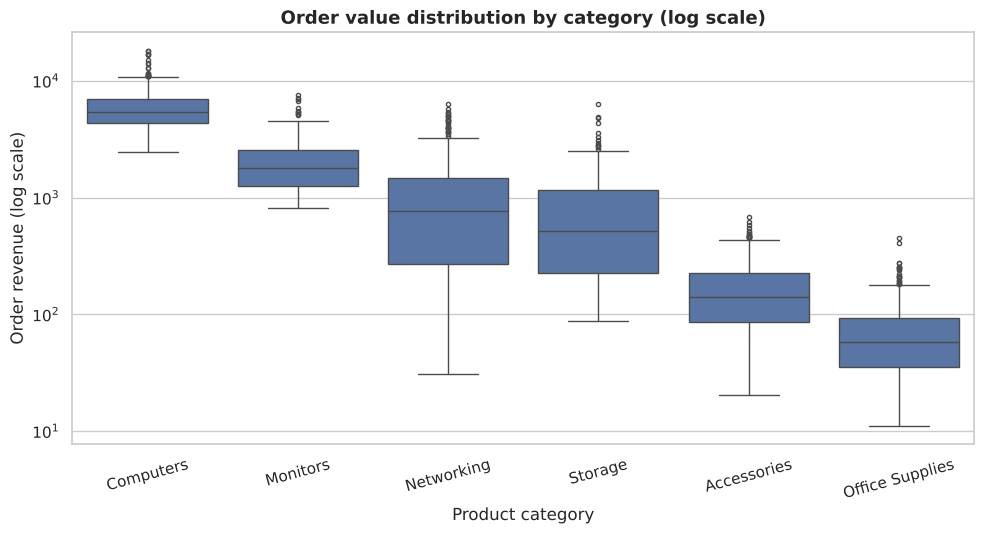

In [25]:
fig,ax=plt.subplots(figsize=(10,5.5))
sns.boxplot(data=df,x='Product Category',y='Revenue',order=df.groupby('Product Category',observed=True)['Revenue'].median().sort_values(ascending=False).index,ax=ax,showfliers=True,flierprops={'markersize':3})
ax.set_yscale('log'); ax.set_title('Order value distribution by category (log scale)'); ax.set_xlabel('Product category'); ax.set_ylabel('Order revenue (log scale)')
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig(IMG+'05_order_value_boxplot.png'); plt.show()

### Chart 6: Do bigger discounts bring bigger orders?

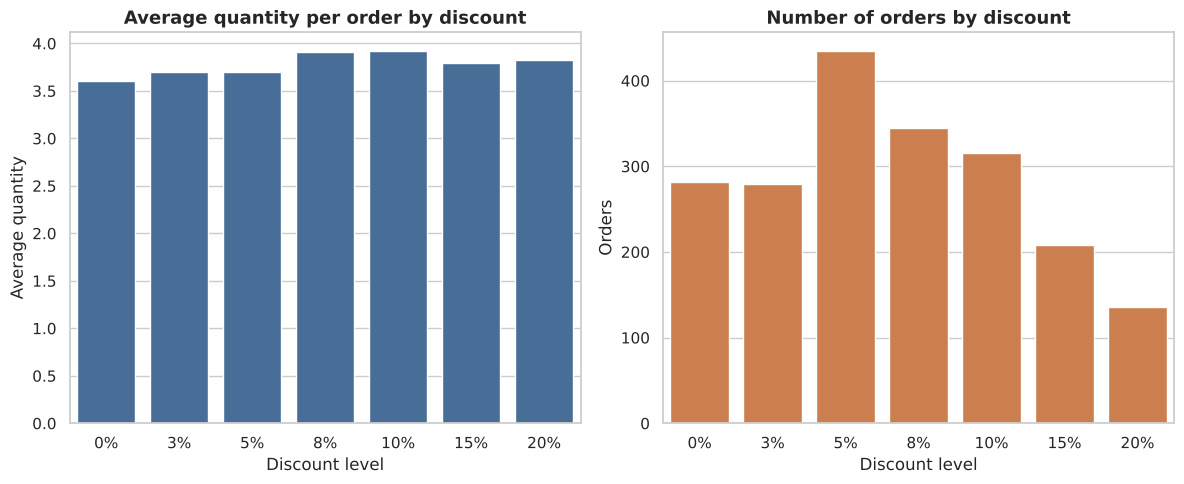

In [26]:
d=df.groupby('Discount').agg(Avg_Qty=('Quantity','mean'),Orders=('Order ID','count')).reset_index()
fig,ax=plt.subplots(1,2,figsize=(12,5))
sns.barplot(data=d,x=(d['Discount']*100).astype(int).astype(str)+'%',y='Avg_Qty',ax=ax[0],color='#3b6ea5')
ax[0].set_title('Average quantity per order by discount'); ax[0].set_xlabel('Discount level'); ax[0].set_ylabel('Average quantity')
sns.barplot(data=d,x=(d['Discount']*100).astype(int).astype(str)+'%',y='Orders',ax=ax[1],color='#e07b39')
ax[1].set_title('Number of orders by discount'); ax[1].set_xlabel('Discount level'); ax[1].set_ylabel('Orders')
plt.tight_layout(); plt.savefig(IMG+'06_discount.png'); plt.show()

### Chart 7: Correlation heatmap

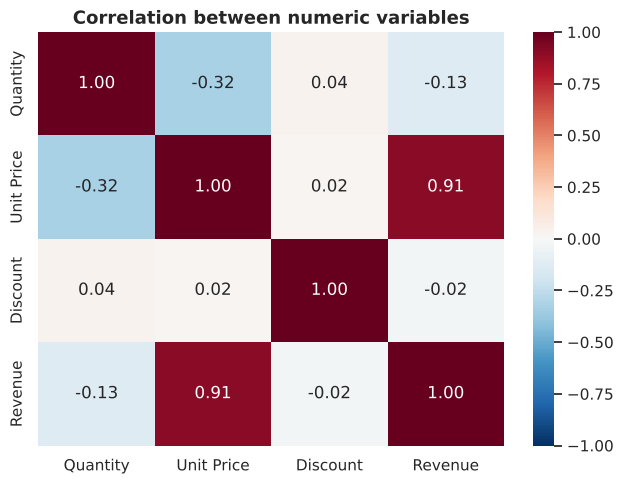

In [27]:
fig,ax=plt.subplots(figsize=(6.5,5))
sns.heatmap(num.corr(),annot=True,fmt='.2f',cmap='RdBu_r',center=0,vmin=-1,vmax=1,ax=ax)
ax.set_title('Correlation between numeric variables'); plt.tight_layout(); plt.savefig(IMG+'07_correlation.png'); plt.show()

### Chart 8: Salesperson revenue ranking

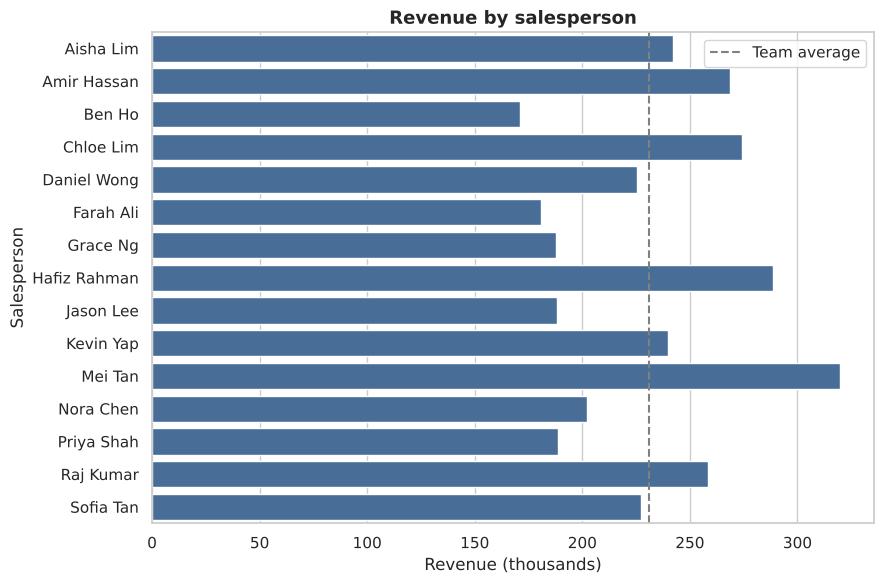

In [28]:
sp=summarise('Salesperson')['Revenue']/1e3
fig,ax=plt.subplots(figsize=(9,6))
sns.barplot(x=sp.values,y=sp.index,ax=ax,color='#3b6ea5'); ax.axvline(sp.mean(),ls='--',color='grey',label='Team average'); ax.legend()
ax.set_title('Revenue by salesperson'); ax.set_xlabel('Revenue (thousands)'); ax.set_ylabel('Salesperson')
plt.tight_layout(); plt.savefig(IMG+'08_salesperson.png'); plt.show()

### Chart 9: Revenue heatmap, region by product category

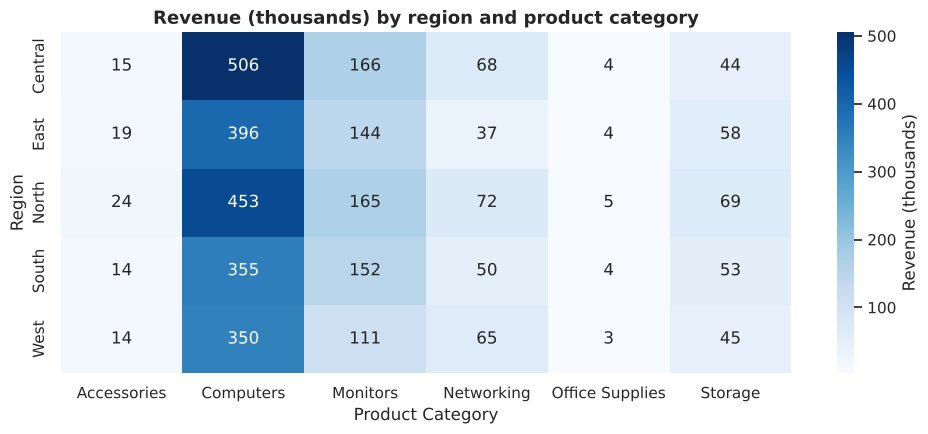

In [29]:
hm=df.pivot_table(index='Region',columns='Product Category',values='Revenue',aggfunc='sum',observed=True)/1e3
fig,ax=plt.subplots(figsize=(10,4.5))
sns.heatmap(hm,annot=True,fmt=',.0f',cmap='Blues',ax=ax,cbar_kws={'label':'Revenue (thousands)'})
ax.set_title('Revenue (thousands) by region and product category'); plt.tight_layout(); plt.savefig(IMG+'09_region_category_heatmap.png'); plt.show()

## 7. Supporting Calculations for Insights

In [30]:
top_sorted = df['Revenue'].sort_values(ascending=False)
n10=int(len(df)*0.10)
print(f'Top 10% of orders ({n10} orders) = {top_sorted.head(n10).sum()/df.Revenue.sum():.1%} of revenue')
comp = df[df['Product Category']=='Computers']
print(f'Computers: {len(comp)/len(df):.1%} of orders but {comp.Revenue.sum()/df.Revenue.sum():.1%} of revenue')
print()
print('Customer type - orders share vs revenue share')
print(pd.concat([df['Customer Type'].value_counts(normalize=True).rename('Order share'),
                 df.groupby('Customer Type',observed=True)['Revenue'].sum().div(df.Revenue.sum()).rename('Revenue share')],axis=1))
print()
m2=df.groupby('Month')['Revenue'].sum()
print('Best month :', m2.idxmax(), f'{m2.max():,.0f}'); print('Weakest    :', m2.idxmin(), f'{m2.min():,.0f}')
print('H1 vs H2   :', f'{m2.loc[1:6].sum():,.0f}', 'vs', f'{m2.loc[7:12].sum():,.0f}')
print('Q4 share   :', f"{df[df.Quarter=='Q4'].Revenue.sum()/df.Revenue.sum():.1%}")
print()
print('Quantity by discount band:'); print(df.groupby('Discount Band',observed=True).agg(Avg_Qty=('Quantity','mean'),Orders=('Order ID','count'),Avg_Rev=('Revenue','mean')))
print('\nCorrelation Discount vs Quantity:', round(df['Discount'].corr(df['Quantity']),3))
print('Discount given on Computers: %.0f' % comp['Discount Amount'].sum(), 'of total %.0f' % df['Discount Amount'].sum())

Top 10% of orders (200 orders) = 43.9% of revenue
Computers: 16.9% of orders but 59.5% of revenue

Customer type - orders share vs revenue share
               Order share  Revenue share
Customer Type                            
Returning             0.66           0.68
New                   0.34           0.32

Best month : 6 373,916
Weakest    : 2 219,187
H1 vs H2   : 1,733,448 vs 1,729,158
Q4 share   : 28.0%

Quantity by discount band:
               Avg_Qty  Orders  Avg_Rev
Discount Band                          
None              3.60     282 1,450.79
1-5%              3.70     714 2,013.01
6-10%             3.92     660 1,614.43
11-20%            3.81     344 1,600.78

Correlation Discount vs Quantity: 0.036
Discount given on Computers: 170595 of total 280963


## 8. Key Insights

1. **Computers carry the business.** Computers are only 16.9% of orders but bring in 59.5% of revenue (about 2.06M of 3.46M). The Gaming Laptop alone earns roughly 666K, around 19% of all revenue.
2. **Low-ticket categories add volume, not value.** Accessories and Office Supplies make up 37% of orders (749 of 2,000) but only 3.0% of revenue. Average order values are about 171 and 78 respectively.
3. **Revenue is concentrated in big orders.** The top 10% of orders (200 orders) produce 43.9% of revenue. Unit price is the main driver of order value (correlation 0.91), while quantity is slightly negative (-0.13) because cheap items are bought in larger quantities.
4. **Corporate Sales is small in volume but large in value.** It has only 333 orders but the highest average order value (about 3,045, nearly 2x Online at 1,410) and a 29.3% revenue share. Online is the largest channel (32.1%) by volume. Marketplace is the weakest on both counts (12.4% of revenue, average order about 1,160).
5. **Regional gaps come from order count, not order size.** Central (23.2%) and North (22.7%) lead. West is last (17.0%) with the fewest orders (330), yet its average order value (1,779) is higher than North's (1,647). Growth in West depends on winning more orders.
6. **Returning customers are the core base.** They place 65.6% of orders and generate 68.4% of revenue, with an average order about 14% higher than new customers (1,807 vs 1,588).
7. **Sales are seasonal but not growing through the year.** June is the peak month (about 374K) and February the weakest (about 219K). November and December are strong again (341K and 322K), and November has the most orders (206). First-half and second-half revenue are nearly identical (1.733M vs 1.729M).
8. **Discounts show no clear volume benefit.** Discounts totalled about 281K (7.5% of gross sales), and about 61% of that was given on Computers. The correlation between discount and quantity is only 0.04, and orders with no discount average 3.6 units against 3.8 to 3.9 for discounted ones, which is a very small difference. Discounts are costing margin without clear evidence they raise order size.
9. **Team performance is uneven.** Mei Tan leads (about 320K) and Ben Ho is lowest (about 171K). Most of the gap is order count, so lead allocation and territory may matter more than individual selling skill.

## 9. Conclusion and Recommendations

**Conclusion.** 2026 revenue of about 3.46M is driven by a small number of high-value Computer orders, mostly sold to returning customers and through Corporate and Online channels. Revenue is stable across the year with a mid-year and year-end peak, and there is no growth trend between the first and second half.

**Recommendations**
- **Protect and grow Computers:** keep stock and pricing focus on the top laptops and all-in-one PCs, since each lost computer order costs far more than many accessory orders.
- **Grow Corporate Sales:** the highest order value per sale; add account management and bundle monitors, networking and storage with computer orders.
- **Review discount policy:** test lower discounts on Computers, where most discount money goes, and measure whether volume actually falls.
- **Lift West and the Marketplace channel:** target more orders rather than larger ones, for example through local promotions and better Marketplace listings.
- **Retain and convert customers:** returning customers spend about 14% more per order; loyalty offers and follow-ups for new customers should pay off.
- **Plan for seasonality:** build campaigns for February and July, the weakest months, and prepare inventory for June and November/December.

**Limitations.** The dataset covers a single year, has no cost or margin data (so profit cannot be judged), and has no customer ID (so repeat purchase behaviour cannot be tracked).